<a href="https://colab.research.google.com/github/benameur21/Visual-Embeddings/blob/main/TP4_Embeddings_Visuels.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/benameur21/Visual-Embeddings.git

Cloning into 'Visual-Embeddings'...
remote: Enumerating objects: 18, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (16/16), done.
remote: Total 18 (delta 7), reused 3 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (18/18), 2.98 MiB | 16.79 MiB/s, done.
Resolving deltas: 100% (7/7), done.


In [2]:
%cd Visual-Embeddings


/content/Visual-Embeddings


In [3]:
!git status

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [4]:
!pip install -q tensorflow-datasets importlib_resources


**Importations**

In [5]:
# Gestion du hasard
import random
# Manipulation numérique
import numpy as np
# Affichage
import matplotlib.pyplot as plt
# Deep Learning
import tensorflow as tf
# Datasets TensorFlow
import tensorflow_datasets as tfds

In [6]:
# Choisir une graine personnelle
SEED = int(
 input("Entrez une SEED personnelle entre 1000 et 999999 : ")
)
# Générateurs utilisés dans les différentes parties
rng1 = random.Random(SEED + 1)
rng2 = random.Random(SEED + 2)
rng3 = random.Random(SEED + 3)
print("SEED utilisée :", SEED)

Entrez une SEED personnelle entre 1000 et 999999 : 202610 
SEED utilisée : 202610


Partie 0 — Découvrir Oxford-IIIT Pet
**bold text**

Charger le dataset


In [7]:
# Charger le jeu d'entraînement
dataset, info = tfds.load(
 "oxford_iiit_pet",
 split="train",
 as_supervised=True, # Retourne (image, label)
 with_info=True # Informations sur le dataset
)
# Noms des races
class_names = info.features["label"].names
print("Nombre de classes :", len(class_names))
print(class_names)


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.N3YGYC_4.0.0/oxford_iiit_pet-train.tfrecord-[0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.N3YGYC_4.0.0/oxford_iiit_pet-test.tfrecord-[0-9…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.
Nombre de classes : 37
['Abyssinian', 'american_bulldog', 'american_pit_bull_terrier', 'basset_hound', 'beagle', 'Bengal', 'Birman', 'Bombay', 'boxer', 'British_Shorthair', 'chihuahua', 'Egyptian_Mau', 'english_cocker_spaniel', 'english_setter', 'german_shorthaired', 'great_pyrenees', 'havanese', 'japanese_chin', 'keeshond', 'leonberger', 'Maine_Coon', 'miniature_pinscher', 'newfoundland', 'Persian', 'pomeranian', 'pug', 'Ragdoll', 'Russian_Blue', 'saint_bernard', 'samoyed', 'scottish_terrier', 'shiba_inu', 'Siamese', 'Sphynx', 'staffordshire_bull_terrier', 'wheaten_terrier', 'yorkshire_terrier']


Afficher quelques images


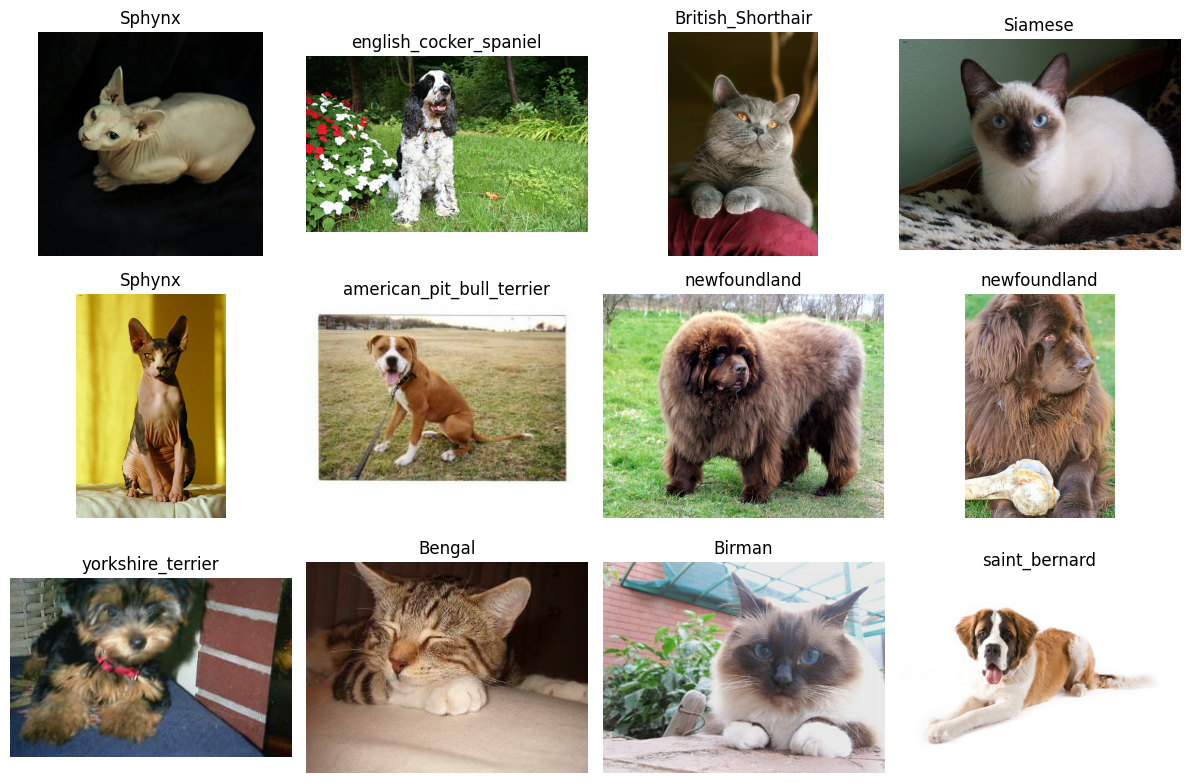

In [8]:
plt.figure(figsize=(12, 8))
# Afficher 12 images
for i, (image, label) in enumerate(dataset.take(12)):
 ax = plt.subplot(3, 4, i + 1)
 # Afficher l'image
 ax.imshow(image.numpy())
 # Afficher la race
 ax.set_title(
 class_names[int(label)]
 )
 ax.axis("off")
plt.tight_layout()
plt.show()

**Partie 1 — Transformer une image en embedding**


Construire l’extracteur

In [9]:
# Charger MobileNetV2 pré-entraîné
base_model = tf.keras.applications.MobileNetV2(
 weights="imagenet",
 # Supprimer le classifieur ImageNet
 include_top=False,
 # Taille des images d'entrée
 input_shape=(224, 224, 3)
)
# Geler le backbone
base_model.trainable = False
embedding_model = tf.keras.Sequential([
 # Extraction des feature maps
 base_model,
 # Feature maps -> vecteur
 tf.keras.layers.GlobalAveragePooling2D()
])
embedding_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

Préparer une image

In [10]:
def prepare_image(image):
 # Redimensionner l'image
 image = tf.image.resize(
 image,
 (224, 224)
 )
 # Conversion en float
 image = tf.cast(
 image,
 tf.float32
 )
 # Prétraitement attendu par MobileNetV2
 image = tf.keras.applications.mobilenet_v2.preprocess_input(
 image
 )
 return image


 Construire un petit ensemble d’images

In [11]:
# Constituer un petit ensemble
sample_pool = list(
 dataset.take(300)
)
print(
 "Nombre d'images disponibles :",
 len(sample_pool)
)


Nombre d'images disponibles : 300


Choisir aléatoirement une image

Indice choisi : 225


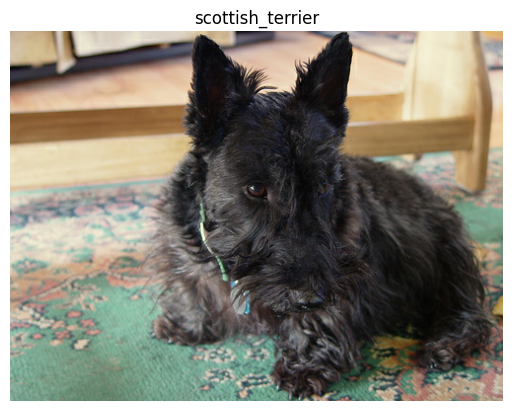

In [12]:
# Choisir un indice aléatoire
sample_index = rng1.randrange(
 len(sample_pool)
)
# Récupérer l'image et son label
sample_image, sample_label = sample_pool[
 sample_index
]
print(
 "Indice choisi :",
 sample_index
)
# Afficher l'image
plt.imshow(
 sample_image.numpy() )
plt.title(
 class_names[int(sample_label)] )
plt.axis("off")
plt.show()

Préparer l’image

In [13]:
# Préparer l'image
x = prepare_image(
 sample_image )
print(
 "Avant ajout du batch :",
 x.shape )

Avant ajout du batch : (224, 224, 3)


In [14]:
# Ajouter la dimension batch
# (224,224,3 -> (1,224,224,3)
x = tf.expand_dims(
 x,
 axis=0 )
print(
 "Après ajout du batch :",
 x.shape )

Après ajout du batch : (1, 224, 224, 3)


Générer l’embedding

In [15]:
# Générer l'embedding
embedding = embedding_model.predict(
 x,
 verbose=0 )
# Afficher sa dimension
print(
 "Dimension de l'embedding :",
 embedding.shape )
# Afficher quelques valeurs
print(
 "10 premières valeurs :" )
print(
 embedding[0][:10] )

Dimension de l'embedding : (1, 1280)
10 premières valeurs :
[1.1784815  1.1647203  0.11852951 0.10596846 1.5036327  0.
 0.         0.5957494  0.3131226  0.        ]


**Partie 2 — Comparer deux images**


 Importer la similarité cosinus

In [16]:
# Comparaison entre vecteurs
from sklearn.metrics.pairwise import cosine_similarity

Fonction permettant d’obtenir un embedding


In [17]:
def get_embedding(image):
 # Préparer l'image
 x = prepare_image(
 image
 )
 # Ajouter le batch
 x = tf.expand_dims(
 x,
 axis=0
 )
 # Calculer l'embedding
 embedding = embedding_model.predict(
 x,
 verbose=0
 )
 # Retourner le vecteur
 return embedding[0]

Constituer une collection

In [18]:
images = []
labels = []
# Récupérer 200 images
for image, label in dataset.take(200):
 images.append(
 image
 )
 labels.append(
 int(label)
 )
print(
 "Nombre d'images :",
 len(images)
)

Nombre d'images : 200


Choisir aléatoirement deux images de même race



In [19]:
# Associer chaque label à ses indices
indices_by_label = {}

for idx, label in enumerate(labels):
    if label not in indices_by_label:
        indices_by_label[label] = []

    indices_by_label[label].append(idx)

In [20]:
# Conserver les races ayant au moins 2 images
eligible_labels = [
 label
 for label, indices in indices_by_label.items()
 if len(indices) >= 2
]
# Choisir aléatoirement une race
selected_label = rng2.choice(
 eligible_labels
)
# Choisir deux images de cette race
idx_A, idx_B = rng2.sample(
 indices_by_label[selected_label],
 2
)


Choisir aléatoirement une image d’une autre race

In [21]:
# Indices appartenant à d'autres races
different_indices = [
 idx
 for idx, label in enumerate(labels)
 if label != selected_label
]
# Choisir une image au hasard
idx_C = rng2.choice(
 different_indices
)

Observer les trois images

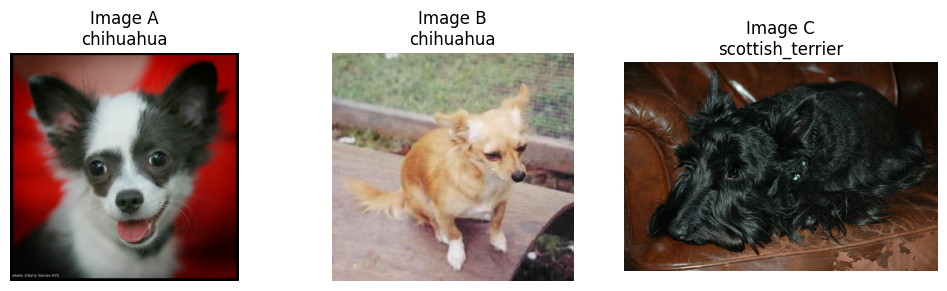

In [22]:
plt.figure(
 figsize=(10, 3)
)
indices = [
 idx_A,
 idx_B,
 idx_C
]
titles = [
 "Image A",
 "Image B",
 "Image C"
]
for i, idx in enumerate(indices):
 ax = plt.subplot(
 1,
 3,
 i + 1
 )
 # Afficher l'image
 ax.imshow(
 images[idx].numpy()
 )
 # Afficher la race
 ax.set_title(
 titles[i]
 + "\n"
 + class_names[labels[idx]]
 )
 ax.axis("off")
plt.tight_layout()
plt.show()

 Générer les embeddings

In [23]:
# Embedding des trois images
embedding_A = get_embedding(
 images[idx_A]
)
embedding_B = get_embedding(
 images[idx_B]
)
embedding_C = get_embedding(
 images[idx_C]
)

 Calculer les similarités

In [24]:
# Similarité A / B
sim_AB = cosine_similarity(
 embedding_A.reshape(1, -1),
 embedding_B.reshape(1, -1)
)[0, 0]
# Similarité A / C
sim_AC = cosine_similarity(
 embedding_A.reshape(1, -1),
 embedding_C.reshape(1, -1)
)[0, 0]


In [25]:
# Afficher les résultats
print(
 "A :",
 class_names[labels[idx_A]]
)
print(
 "B :",
 class_names[labels[idx_B]]
)
print(
 "C :",
 class_names[labels[idx_C]]
)
print()
print(
 "sim(A,B) =",
 round(sim_AB, 4)
)
print(
 "sim(A,C) =",
 round(sim_AC, 4)
)

A : chihuahua
B : chihuahua
C : scottish_terrier

sim(A,B) = 0.4419
sim(A,C) = 0.2756


**Partie 3 — Construire un mini moteur de recherche visuelle**

 Construire la galerie

In [26]:
# Nombre d'images de la galerie
GALLERY_SIZE = 300

In [27]:
gallery_images = []
gallery_labels = []
# Constituer la galerie
for image, label in dataset.take(GALLERY_SIZE):
 gallery_images.append(
 image
 )
 gallery_labels.append(
 int(label)
 )
print(
 "Nombre d'images :",
 len(gallery_images)
)


Nombre d'images : 300


Préparer toutes les images

In [28]:
# Préparer les images
gallery_batch = tf.stack([
 prepare_image(image)
 for image in gallery_images
])
print(
 gallery_batch.shape
)


(300, 224, 224, 3)


Calculer tous les embeddings


In [29]:
# Calculer les embeddings
gallery_embeddings = embedding_model.predict(
 gallery_batch,
 verbose=1
)


10/10 ━━━━━━━━━━━━━━━━━━━━ 9s 397ms/step


In [30]:
# Vérifier les dimensions
print(
 gallery_embeddings.shape
)


(300, 1280)


Choisir aléatoirement l’image requête

In [31]:
# Choisir un indice au hasard
QUERY_INDEX = rng3.randrange(
 GALLERY_SIZE
)
print(
 "QUERY_INDEX :",
 QUERY_INDEX
)

QUERY_INDEX : 47


In [32]:
# Récupérer l'image
query_image = gallery_images[
 QUERY_INDEX
]
query_label = gallery_labels[
 QUERY_INDEX
]

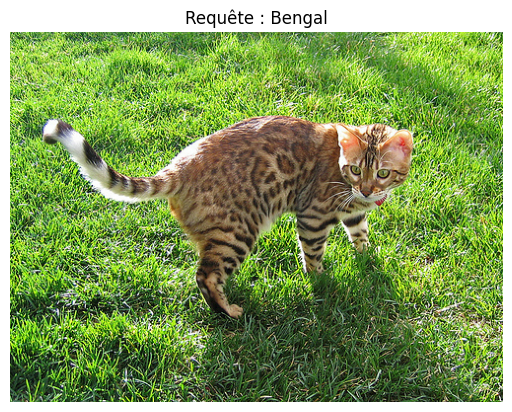

In [33]:
# Afficher la requête
plt.imshow(
 query_image.numpy()
)
plt.title(
 "Requête : "
 + class_names[query_label]
)
plt.axis("off")
plt.show()

Récupérer l’embedding de la requête

In [34]:
# Embedding de la requête
query_embedding = gallery_embeddings[
 QUERY_INDEX
]

Calculer les similarités avec toute la galerie

In [35]:
# Comparer la requête avec les 300 images
similarities = cosine_similarity(
 query_embedding.reshape(1, -1),
 gallery_embeddings
)[0]

Visualiser la distribution des similarités

In [36]:
# Trier les similarités
sorted_similarities = np.sort(
 similarities
)[::-1]

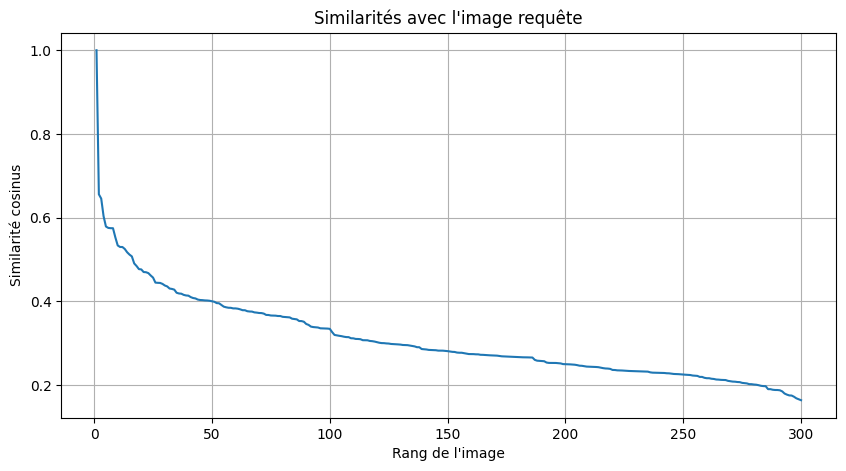

In [37]:
# Afficher la courbe
plt.figure(
 figsize=(10, 5)
)
plt.plot(
 range(1, len(sorted_similarities) + 1),
 sorted_similarities
)
plt.xlabel(
 "Rang de l'image"
)
plt.ylabel(
 "Similarité cosinus"
)
plt.title(
 "Similarités avec l'image requête"
)
plt.grid()
plt.show()

In [38]:
# Seuil de similarité
THRESHOLD = 0.80
# Compter les images dépassant le seuil
nb_similar = np.sum(
 similarities >= THRESHOLD
)
# Retirer l'image requête elle-même
nb_similar = nb_similar - 1
print(
 "Nombre d'images avec une similarité >= 0.80 :",
 nb_similar
)

Nombre d'images avec une similarité >= 0.80 : 0


Vérifier la similarité avec elle-même

In [39]:
# Similarité avec elle-même
print(
 similarities[QUERY_INDEX]
)


1.0


Exclure l’image requête

In [40]:
# Copier les scores
scores = similarities.copy()
# Exclure la requête
scores[QUERY_INDEX] = -np.inf

Trouver le Top-5

In [41]:
# Trier les scores
top5_indices = np.argsort(
 scores
)[::-1][:5]
print(
 top5_indices
)

[141 284  60 205 159]


Afficher les résultats

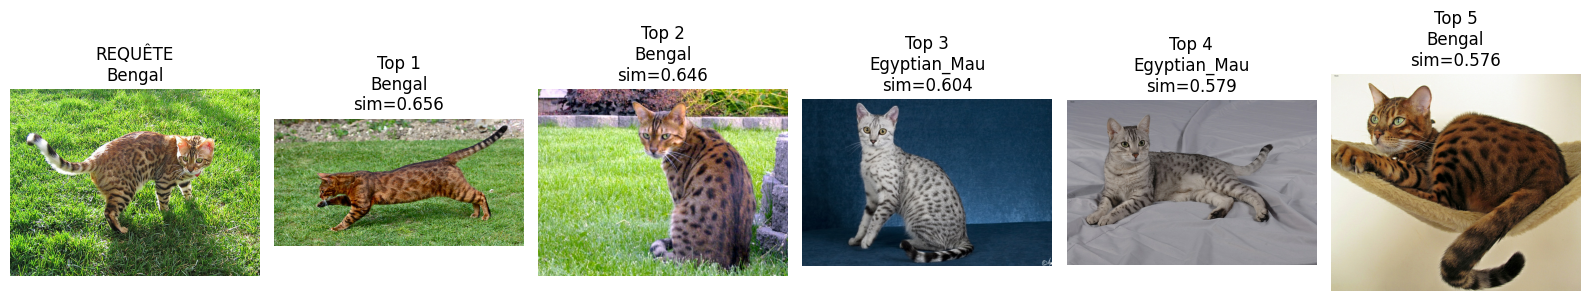

In [42]:
plt.figure(
 figsize=(16, 4)
)
# Image requête
ax = plt.subplot( 1, 6, 1)
ax.imshow( query_image.numpy() )
ax.set_title(
 "REQUÊTE\n"
 + class_names[query_label]
)
ax.axis("off")
# Afficher les 5 voisins
for rank, idx in enumerate(
 top5_indices,
 start=1
):
 ax = plt.subplot(
 1,
 6,
 rank + 1
 )
 ax.imshow(
 gallery_images[idx].numpy()
 )
 ax.set_title(
 f"Top {rank}\n"
 f"{class_names[gallery_labels[idx]]}\n"
 f"sim={scores[idx]:.3f}"
 )
 ax.axis("off")
plt.tight_layout()
plt.show()

**PCA**

In [43]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

In [44]:
pca = PCA(n_components=2)
embeddings_2d = pca.fit_transform(gallery_embeddings)


Prédiction avant l'expérience :
Je prédis que la race la plus compacte sera le Sphynx


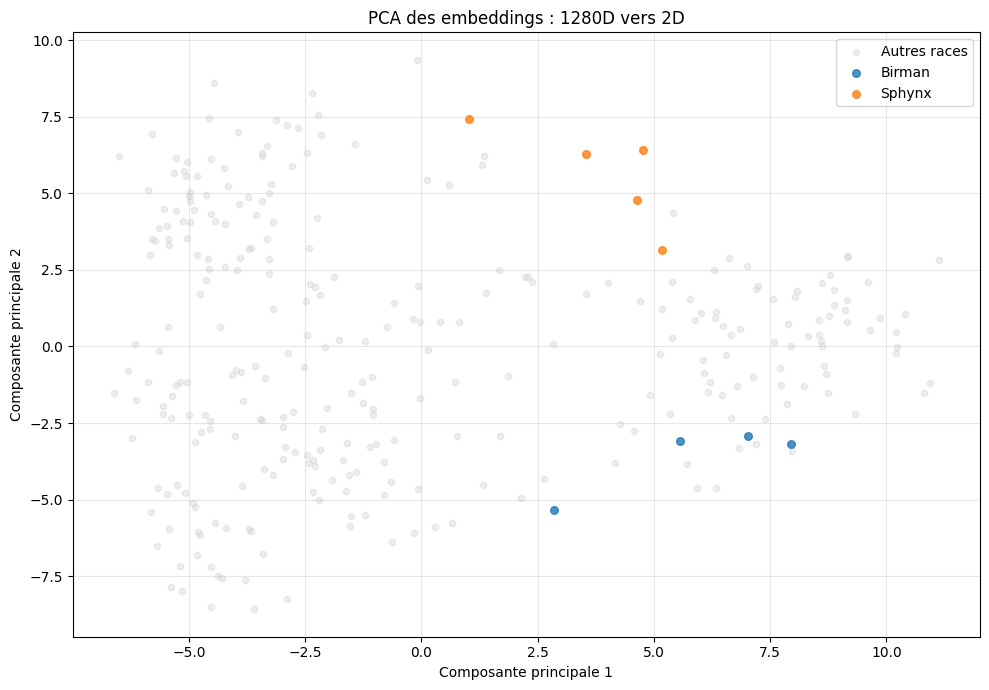

Variance expliquée par la composante 1 : 8.35 %
Variance expliquée par la composante 2 : 4.88 %
Variance totale expliquée : 13.24 %


In [48]:

races_choisies = ["Birman", "Sphynx"]

print("Prédiction avant l'expérience :")
print("Je prédis que la race la plus compacte sera le Sphynx")

labels_races = np.array([
    class_names[label] for label in gallery_labels
])

plt.figure(figsize=(10, 7))

mask_autres = ~np.isin(labels_races, races_choisies)

plt.scatter(
    embeddings_2d[mask_autres, 0],
    embeddings_2d[mask_autres, 1],
    color="lightgray",
    alpha=0.4,
    s=20,
    label="Autres races"
)

for race in races_choisies:
    idx = labels_races == race

    plt.scatter(
        embeddings_2d[idx, 0],
        embeddings_2d[idx, 1],
        alpha=0.8,
        s=30,
        label=race
    )

plt.xlabel("Composante principale 1")
plt.ylabel("Composante principale 2")
plt.title("PCA des embeddings : 1280D vers 2D")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Variance expliquée par la composante 1 :",
      round(pca.explained_variance_ratio_[0] * 100, 2), "%")

print("Variance expliquée par la composante 2 :",
      round(pca.explained_variance_ratio_[1] * 100, 2), "%")

print("Variance totale expliquée :",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")


**K-Means**

In [49]:
from sklearn.cluster import KMeans
import numpy as np

In [50]:
# Appliquer K-Means aux embeddings
kmeans = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

In [51]:
clusters = kmeans.fit_predict(gallery_embeddings)

# Afficher le nombre d'images dans chaque cluster
for i in range(10):
    nombre_images = np.sum(clusters == i)
    print(f"Cluster {i} : {nombre_images} images")

Cluster 0 : 17 images
Cluster 1 : 21 images
Cluster 2 : 35 images
Cluster 3 : 34 images
Cluster 4 : 24 images
Cluster 5 : 35 images
Cluster 6 : 32 images
Cluster 7 : 54 images
Cluster 8 : 20 images
Cluster 9 : 28 images


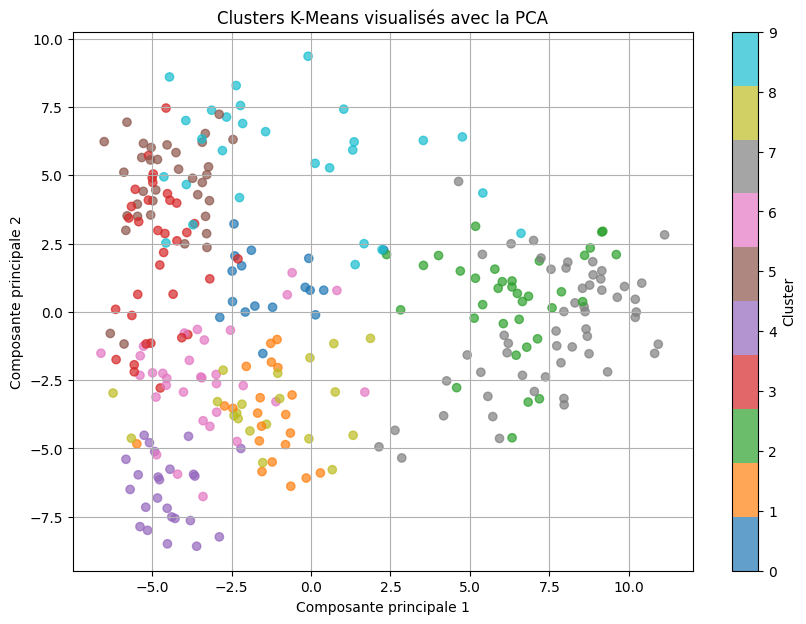

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.scatter(
    embeddings_2d[:, 0],
    embeddings_2d[:, 1],
    c=clusters,
    cmap="tab10",
    alpha=0.7
)

plt.xlabel("Composante principale 1")
plt.ylabel("Composante principale 2")
plt.title("Clusters K-Means visualisés avec la PCA")
plt.colorbar(label="Cluster")
plt.grid()
plt.show()

In [57]:
from collections import Counter

# Analyser le cluster 0 (tu peux choisir un autre numéro)
cluster_analyse = 9

labels_cluster = [
    class_names[int(gallery_labels[i])]
    for i in range(len(clusters))
    if clusters[i] == cluster_analyse
]

print(f"Cluster {cluster_analyse}")
for race, effectif in Counter(labels_cluster).most_common(5):
    print(f"{race} : {effectif} images")

Cluster 9
american_pit_bull_terrier : 8 images
miniature_pinscher : 7 images
Sphynx : 3 images
chihuahua : 2 images
beagle : 2 images
